<span style="float: left;padding: 1.3em">![logo](../logo.png)</span>

# Gravitational Wave Open Data Workshop

## Tutorial 1.2: Acessando dados abertos com GWpy e PyCBC

Este tutorial descreverá como acessar dados abertos usando GWpy e PyCBC.

Veja este tutorial em [Google Colaboratory](https://colab.research.google.com/github/gw-odw/odw/blob/main/Tutorials/01_Accessing_Open_Data/Tuto_1.2_Accessing_Open_Data_with_GWpy_PyCBC.ipynb) ou abrindo [mybinder](https://mybinder.org/v2/gh/gw-odw/odw/HEAD).


In [2]:
# Essas duas linhas servem apenas para evitar alguns avisos inofensivos ao importar pacotes.
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

## Instalação (execute apenas se estiver utilizando uma plataforma em nuvem, como o Google Colab, ou se ainda não tiver realizado a instalação!)

> ⚠️ **Warning**: Reinicie o ambiente de execução após executar a célula abaixo.
>
> Para isso, clique em "Ambiente de execução" no menu e escolha "Reiniciar e executar tudo".
>
> Você poderá ver mensagens de erro, mas a instalação geralmente funciona.
> Se tiver problemas, por favor [report an issue](https://github.com/gw-odw/odw/issues).

In [2]:
# -- Descomente a linha a seguir se estiver executando no Google Colab.
#! pip install -q 'gwpy==3.0.14' 'PyCBC==2.10.0' 'cryptography==43.0.0'

## Introdução

Já vimos que o módulo `gwosc` pode ser usado para consultar quais dados estão disponíveis no [GWOSC](https://gwosc.org/data/).
O próximo passo é, de fato, ler alguns dados abertos.

Apresentaremos dois pacotes para fazer isso:
- [GWpy](https://gwpy.readthedocs.io/en/v3.0.14/), um pacote Python para astrofísica gravitacional.
- [PyCBC](https://pycbc.org/), um pacote de software utilizado para explorar fontes astrofísicas de ondas gravitacionais.

Nós os utilizaremos nos próximos tutoriais, mas não podemos apresentá-los em detalhes.
Caso surja algum problema, consulte a documentação.

In [4]:
# A primeira importação do gwpy pode levar algum tempo (especialmente em plataformas de nuvem).
# Isso ocorre principalmente porque o matplotlib leva certo tempo para ser importado (isso é normal).
import gwpy
print("GWpy version: ", gwpy.__version__)
import pycbc
print("PyCBC version:", pycbc.__version__)

GWpy version:  3.0.14
PyCBC version: 2.10.0


## Acesso a Dados Abertos com o GWpy

### Uma nota sobre programação orientada a objetos

Antes de nos aprofundarmos muito, vale a pena fazer uma breve introdução sobre programação orientada a objetos (OOP).
[GWpy](https://gwpy.readthedocs.io/en/v3.0.14/index.html) é fortemente orientado a objetos, o que significa que quase todo o código que você executa usando o GWpy baseia-se em um objeto de algum tipo, por exemplo, [`TimeSeries`](https://gwpy.readthedocs.io/en/v3.0.14/api/gwpy.timeseries.TimeSeries/#gwpy.timeseries.TimeSeries).
A maioria dos métodos (funções) que utilizaremos está associada a um objeto, em vez de existir de forma isolada; isso significa que você deve ter uma boa noção do tipo de dados com o qual está lidando (sem precisar consultar a documentação!).

Para uma visão geral rápida da programação orientada a objetos em Python, consulte [this blog post by Jeff Knupp](https://medium.com/hackernoon/improve-your-python-python-classes-and-object-oriented-programming-d09ff461168d).

### Encontrar dados abertos

Vamos tentar obter alguns dados para o GW190412, a primeira detecção de um sinal de onda gravitacional proveniente de um sistema binário de buracos negros (BBH) com massas significativamente desiguais.

Podemos usar o método [TimeSeries.fetch_open_data](https://gwpy.readthedocs.io/en/v3.0.14/api/gwpy.timeseries.TimeSeries/#gwpy.timeseries.TimeSeries.fetch_open_data)  para baixar dados diretamente de https://gwosc.org, mas precisamos saber os tempos GPS.
Podemos consultar o tempo GPS de um evento da seguinte forma:

In [5]:
from gwosc.datasets import event_gps
gps = event_gps('GW190412')
print(gps)

1239082262.1


Agora podemos construir um segmento GPS `[início, fim)` de 10 segundos em torno desse instante, utilizando números inteiros por conveniência:

In [6]:
start, stop = segment = (int(gps)-5, int(gps)+5)
print(segment)

(1239082257, 1239082267)


Agora podemos consultar os dados completos.
Para este exemplo, optamos por recuperar os dados do interferômetro LIGO-Livingston, utilizando o identificador `'L1'`.

In [7]:
from gwpy.timeseries import TimeSeries
ldata = TimeSeries.fetch_open_data('L1', *segment, verbose=True)
print(ldata)

Fetched 1 URLs from gwosc.org for [1239082257 .. 1239082267))
Reading data... [Done]
TimeSeries([-8.42597565e-19, -8.52437103e-19, -8.60738804e-19,
            ...,  1.38850270e-19,  1.37760541e-19,
             1.38094202e-19]
           unit: dimensionless,
           t0: 1239082257.0 s,
           dt: 0.000244140625 s,
           name: Strain,
           channel: None)


##### O parâmetro `verbose=True` nos permite ver que o GWpy identificou um arquivo contendo os dados para o intervalo especificado, realizou o download e carregou os dados.
Os arquivos não são armazenados permanentemente; portanto, na próxima vez que você fizer a mesma chamada, o download será realizado novamente. No entanto, se você prevê que repetirá a mesma chamada várias vezes, pode utilizar `cache=True` para salvar o arquivo em seu computador.

Observações:

*   Para controlar o conjunto de dados (*dataset*) de origem das informações, você pode utilizar o argumento `dataset`. Recomenda-se utilizar dados provenientes de uma *run* (campanha de observação), caso estejam disponíveis, pois eles contêm a versão mais atualizada da calibração. Para verificar qual *run* estava ativa no período de interesse, basta utilizar o método `find_datasets` do pacote `gwosc` — abordado no tutorial anterior — especificando `type='run'` e `segment=segment`. Por exemplo, para o segmento utilizado neste tutorial, os dois conjuntos de dados disponíveis são [`'O3a_16KHZ_R1'`, `'O3a_4KHZ_R1'`]. Para a amostragem a 4 kHz, o comando completo para obter dados deste conjunto de dados é, então: `TimeSeries.fetch_open_data('L1', *segment, verbose=True, dataset='O3a_4KHZ_R1')`.

* Para ler dados de um arquivo local em vez de do servidor do GWOSC, podemos usar o método [`TimeSeries.read`](https://gwpy.readthedocs.io/en/v3.0.14/api/gwpy.timeseries.TimeSeries/#gwpy.timeseries.TimeSeries.read).

Já baixamos dados reais do LIGO para o GW190412! Estes são os dados efetivos utilizados na análise dessa fusão de buracos negros binários.

Para verificar se tudo está correto, podemos facilmente criar um gráfico, usando o método [`plot()`](https://gwpy.readthedocs.io/en/v3.0.14/plot/) `data` do `TimeSeries`.

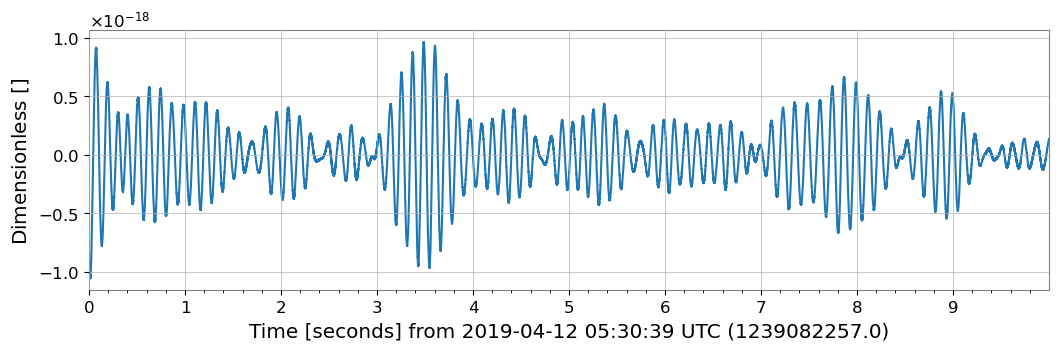

In [8]:
plot = ldata.plot()

## Acesso a Dados Abertos com PyCBC

PyCBC também propõe uma interface orientada a objetos.
Em particular, também oferece uma classe [`TimeSeries`](https://pycbc.org/pycbc/latest/html/pycbc.types.html#pycbc.types.timeseries.TimeSeries) que é semelhante, mas diferente daquela do GWpy.

### Encontrar dados abertos

Da mesma forma, vamos tentar obter alguns para GW190412.

Podemos usar o método [read_strain_gwosc](https://pycbc.org/pycbc/latest/html/pycbc.frame.html#pycbc.frame.gwosc.read_strain_gwosc) para baixar dados diretamente de https://gwosc.org.
Como antes, precisamos saber os tempos GPS, então vamos reutilizá-los.

In [9]:
from pycbc.frame.gwosc import read_strain_gwosc

ldata = read_strain_gwosc('L1', *segment)

Os arquivos não são armazenados permanentemente; portanto, na próxima vez que você fizer a mesma chamada, eles serão baixados novamente.
Além disso, este método baixa dados amostrados a 16 kHz, o que leva mais tempo e consome mais memória.
Pode ser mais eficiente baixar os dados com o `GWpy` e convertê-los usando `to_pycbc()`.

Observações:

* Para ler dados de um arquivo local em vez do servidor GWOSC, podemos usar o método [`read_frame`](https://pycbc.org/pycbc/latest/html/pycbc.frame.html#pycbc.frame.frame.read_frame).

Já baixamos dados reais do LIGO para o GW190412! Estes são os dados efetivos utilizados na análise dessa fusão de buracos negros binários.

Para verificar se tudo está correto, podemos facilmente criar um gráfico, usando o método [`plot()`](https://gwpy.readthedocs.io/en/v3.0.14/api/gwpy.timeseries.TimeSeries/#gwpy.timeseries.TimeSeries.plot) da classe `TimeSeries`.
Veja também [this tutorial](https://gwpy.readthedocs.io/en/v3.0.14/plot/).

Text(0, 0.5, 'Strain (dimensionless)')

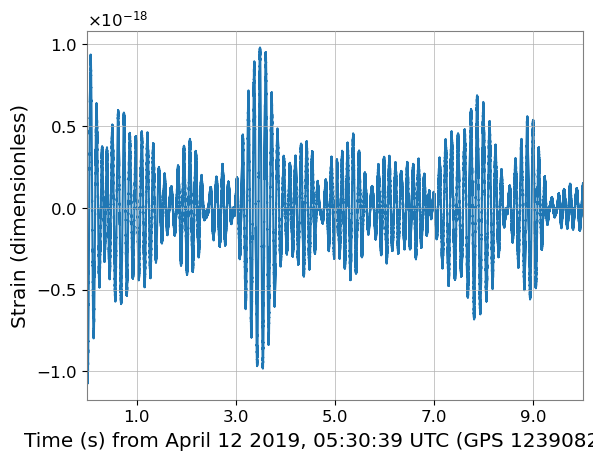

In [10]:
from lal.gpstime import gps_to_str

line = ldata.plot()
figure = line[0].figure
axis = figure.gca()
ticks = axis.get_xticks()
axis.set_xticks(ticks, labels=(ticks - start))
axis.set_xlim(start, stop)
axis.set_xlabel("Time (s) from {0} (GPS {1})".format(gps_to_str(start), start))
axis.set_ylabel("Strain (dimensionless)")

PyCBC contém uma interface para o [GWOSC catalog](https://gwosc.org/eventapi/), assim, você pode acessar facilmente os dados e parâmetros dos sinais de ondas gravitacionais publicados.
Por exemplo, para baixar dados de deformação, você pode usar o método [strain](https://pycbc.org/pycbc/latest/html/pycbc.catalog.html#pycbc.catalog.Merger.strain) da classe [Merger](https://pycbc.org/pycbc/latest/html/pycbc.catalog.html#pycbc.catalog.Merger) .
Isso baixará os segmentos de 32 segundos em torno do evento.

Text(0, 0.5, 'Strain (dimensionless)')

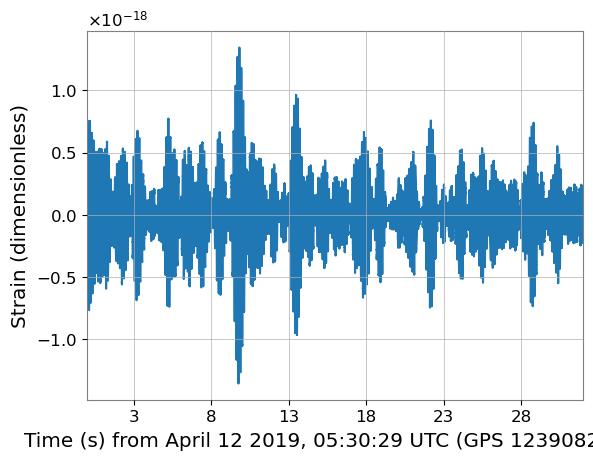

In [11]:
from pycbc.catalog import Merger

GW190412 = Merger('GW190412')
segment = GW190412.strain('L1')
line = segment.plot()
figure = line[0].figure
axis = figure.gca()
ticks = axis.get_xticks()
axis.set_xticks(ticks, labels=(ticks - segment.start_time))
axis.set_xlim(segment.start_time.gpsSeconds, segment.end_time.gpsSeconds)
axis.set_xlabel("Time (s) from {0} (GPS {1})".format(gps_to_str(segment.start_time), segment.start_time))
axis.set_ylabel("Strain (dimensionless)")

## Perguntas do Quiz

Por favor, tente realizar os exercícios a seguir usando essa interface e insira sua resposta no Thinkific.

### Pergunta 1

Ao observar os dados do LIGO-Livingston no domínio do tempo, a amplitude de pico do sinal de onda gravitacional do evento GW190412 ocorre no centro da figura — isto é, aproximadamente 5 segundos após o início do segmento. Esse pico é indetectável a olho nu em relação ao ruído de fundo. Gere os gráficos dos dados dos detectores LIGO-Hanford e Virgo referentes ao GW190412. Ao examinar esses novos gráficos, você consegue identificar visualmente um pico de sinal? Você pode utilizar o GWpy ou o PyCBC.